# Heart Disease Prediction: Logistic Regression vs SVM vs Random Forest vs XGBoost

This notebook:
1. Loads the heart disease dataset (`Heart-Diseas.csv`) and removes duplicate rows.
2. Splits the data into train and test sets before any fitting.
3. Tunes four classifiers with 5-fold cross-validation on the training data only.
4. Compares all models on cross-validation and on the untouched test set.
5. Shows ROC curves, Precision-Recall curves, confusion matrices, per-model reports, and feature importance.
6. Saves the best model and the results tables.

**Target:** `1` = heart disease present, `0` = absent.

## 1. Setup

In [18]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
TARGET = "target"
NUM_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CAT_COLS = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

## 2. Load the data


In [19]:
DATA_PATH = "Heart_Diseas.csv"

if not os.path.exists(DATA_PATH):
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]

df_raw = pd.read_csv(DATA_PATH)
print("Shape (raw):", df_raw.shape)
print("Missing values:", int(df_raw.isna().sum().sum()))
df_raw.head()

Shape (raw): (1025, 14)
Missing values: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 3. Exploratory data analysis

In [20]:
n_dup = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {n_dup}")
print(f"Unique records: {len(df)}")
print("\nClass balance:")
print(df[TARGET].value_counts().rename({0: "No disease (0)", 1: "Disease (1)"}))

df.describe().T.round(2)

Duplicate rows removed: 723
Unique records: 302

Class balance:
target
Disease (1)       164
No disease (0)    138
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.42,9.05,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.68,0.47,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.96,1.03,0.0,0.00,1.0,2.00,3.0
trestbps,302.0,131.60,17.56,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.50,51.75,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.15,0.36,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.53,0.53,0.0,0.00,1.0,1.00,2.0
thalach,302.0,149.57,22.90,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.33,0.47,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.04,1.16,0.0,0.00,0.8,1.60,6.2


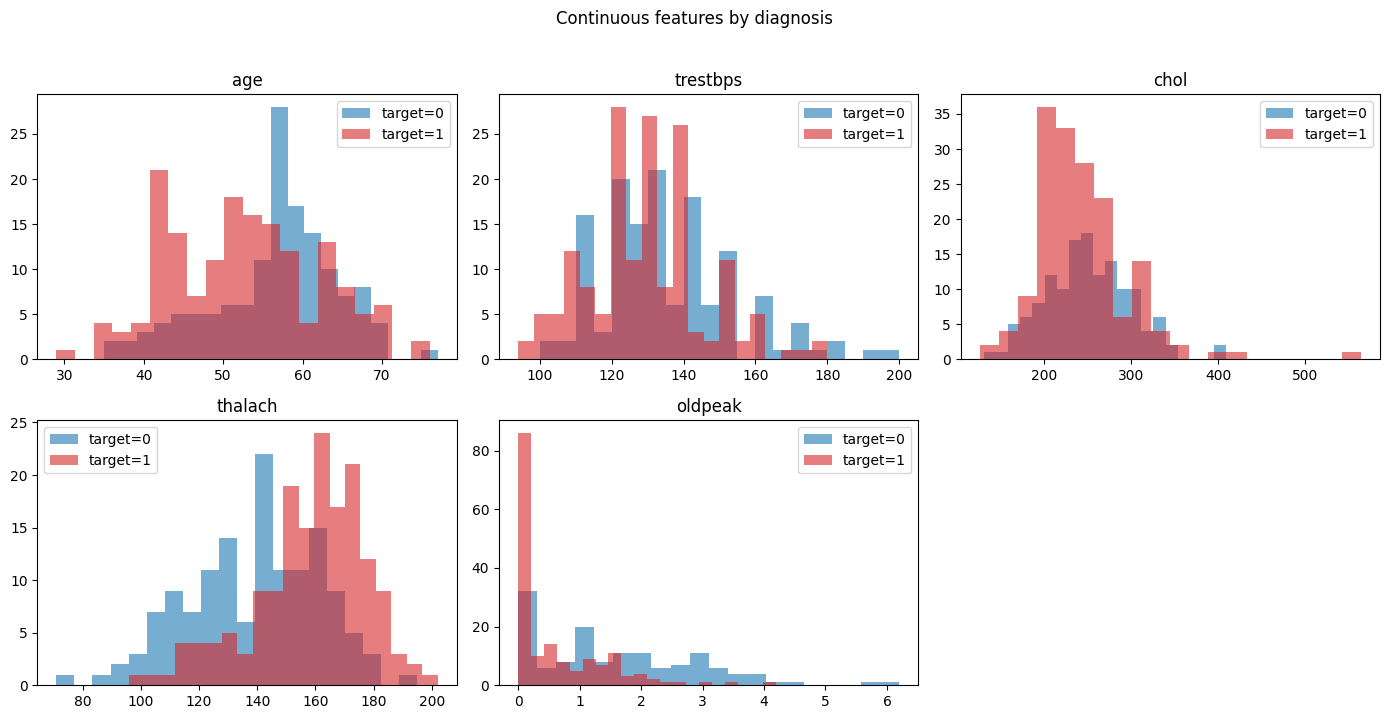

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    for label, color in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(df.loc[df[TARGET] == label, col], bins=20, alpha=0.6,
                color=color, label=f"target={label}")
    ax.set_title(col)
    ax.legend()
axes.ravel()[-1].axis("off")
fig.suptitle("Continuous features by diagnosis", y=1.02)
fig.tight_layout()
plt.show()

## 4. Train/test split and preprocessing

In [23]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train size:", X_train.shape, "| Test size:", X_test.shape)

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), NUM_COLS),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), CAT_COLS),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train size: (241, 13) | Test size: (61, 13)


## 5. Define the algorithms and hyperparameter grids

In [24]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"clf__C": [0.01, 0.1, 1, 10]},
    ),
    "SVM": (
        SVC(kernel="rbf", probability=True, class_weight="balanced",
            random_state=RANDOM_STATE),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced",
                               random_state=RANDOM_STATE, n_jobs=-1),
        {"clf__n_estimators": [200, 400],
         "clf__max_depth": [None, 4, 8],
         "clf__min_samples_leaf": [1, 3]},
    ),
}

try:
    from xgboost import XGBClassifier
    candidates["XGBoost"] = (
        XGBClassifier(eval_metric="logloss", scale_pos_weight=neg / pos,
                      random_state=RANDOM_STATE, n_jobs=-1),
        {"clf__n_estimators": [200, 400],
         "clf__learning_rate": [0.03, 0.1],
         "clf__max_depth": [2, 3, 4],
         "clf__subsample": [0.8, 1.0]},
    )
except ImportError:
    print("XGBoost is not installed. Re-run the install cell and restart the runtime.")

print("Algorithms:", list(candidates.keys()))

Algorithms: ['Logistic Regression', 'SVM', 'Random Forest', 'XGBoost']


## 6. Train, tune, and evaluate every algorithm

In [25]:
results = []
fitted = {}
test_proba = {}
fold_scores = {}

for name, (model, grid) in candidates.items():
    print(f"Tuning {name} ...")
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)

    best = search.best_estimator_
    proba = best.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)

    fitted[name] = best
    test_proba[name] = proba
    fold_scores[name] = [search.cv_results_[f"split{i}_test_score"][search.best_index_]
                         for i in range(cv.get_n_splits())]

    results.append({
        "Model": name,
        "CV ROC-AUC": search.best_score_,
        "CV ROC-AUC std": np.std(fold_scores[name]),
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred),
        "Test Recall": recall_score(y_test, pred),
        "Test F1": f1_score(y_test, pred),
        "Best params": search.best_params_,
    })

print("Done.")

Tuning Logistic Regression ...
Tuning SVM ...
Tuning Random Forest ...
Tuning XGBoost ...
Done.


## 7. Comparison of all algorithms

In [26]:
results_df = pd.DataFrame(results).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
metric_cols = ["CV ROC-AUC", "CV ROC-AUC std", "Test ROC-AUC", "Test PR-AUC",
               "Test Accuracy", "Test Precision", "Test Recall", "Test F1"]

display_df = results_df.copy()
display_df[metric_cols] = display_df[metric_cols].round(4)
display_df

,Model,CV ROC-AUC,CV ROC-AUC std,Test ROC-AUC,Test PR-AUC,Test Accuracy,Test Precision,Test Recall,Test F1,Best params
0,Logistic Regression,0.9275,0.0334,0.9048,0.9225,0.8689,0.9032,0.8485,0.8750,{'clf__C': 1}
1,SVM,0.9219,0.0323,0.8907,0.9071,0.8361,0.8485,0.8485,0.8485,"{'clf__C': 10, 'clf__gamma': 0.01}"
2,Random Forest,0.9163,0.0458,0.8939,0.9172,0.7869,0.8125,0.7879,0.8000,"{'clf__max_depth': 4, 'clf__min_samples_leaf':..."
3,XGBoost,NaN,NaN,0.8734,0.8990,0.7541,0.7812,0.7576,0.7692,"{'clf__learning_rate': 0.03, 'clf__max_depth':..."


In [27]:
results_df.to_csv("model_comparison.csv", index=False)
print("Saved model_comparison.csv")

Saved model_comparison.csv


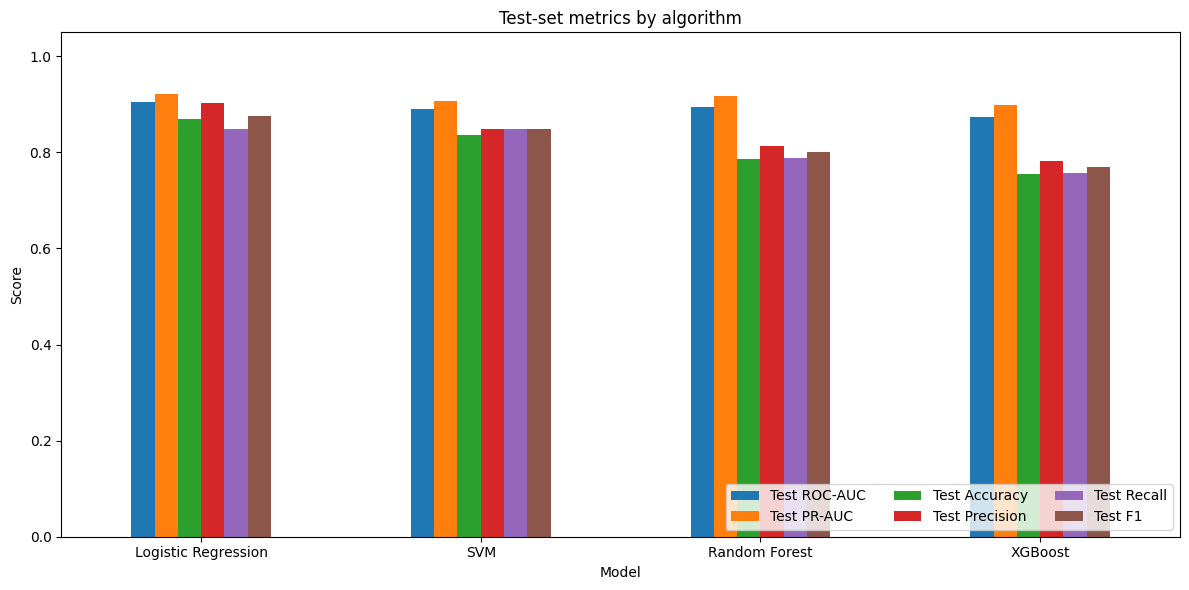

In [28]:
test_metrics = ["Test ROC-AUC", "Test PR-AUC", "Test Accuracy",
                "Test Precision", "Test Recall", "Test F1"]

ax = results_df.set_index("Model")[test_metrics].plot(kind="bar", figsize=(12, 6), rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Test-set metrics by algorithm")
ax.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

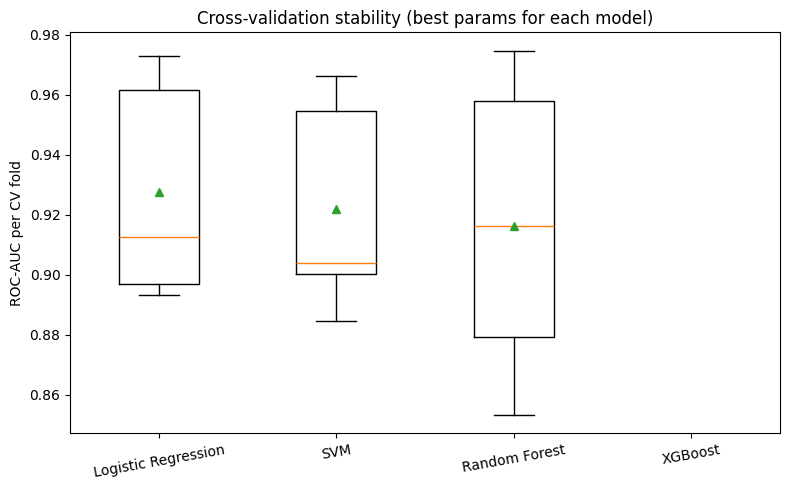

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
names = results_df["Model"].tolist()
ax.boxplot([fold_scores[n] for n in names], showmeans=True)
ax.set_xticks(range(1, len(names) + 1))
ax.set_xticklabels(names)
ax.set_ylabel("ROC-AUC per CV fold")
ax.set_title("Cross-validation stability (best params for each model)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## 8. ROC and Precision-Recall curves

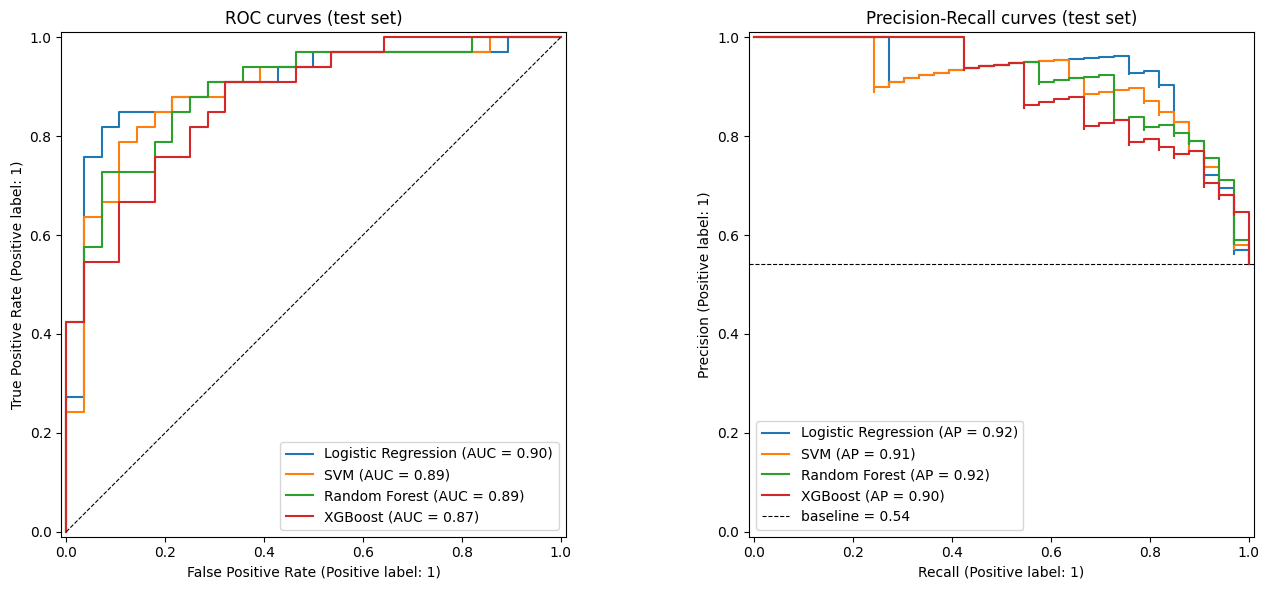

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for name, proba in test_proba.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=ax2)

ax1.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax1.set_title("ROC curves (test set)")
ax2.axhline(y_test.mean(), color="k", linestyle="--", linewidth=0.8,
            label=f"baseline = {y_test.mean():.2f}")
ax2.set_title("Precision-Recall curves (test set)")
ax2.legend()
plt.tight_layout()
plt.show()

## 9. Confusion matrices (decision threshold = 0.5)

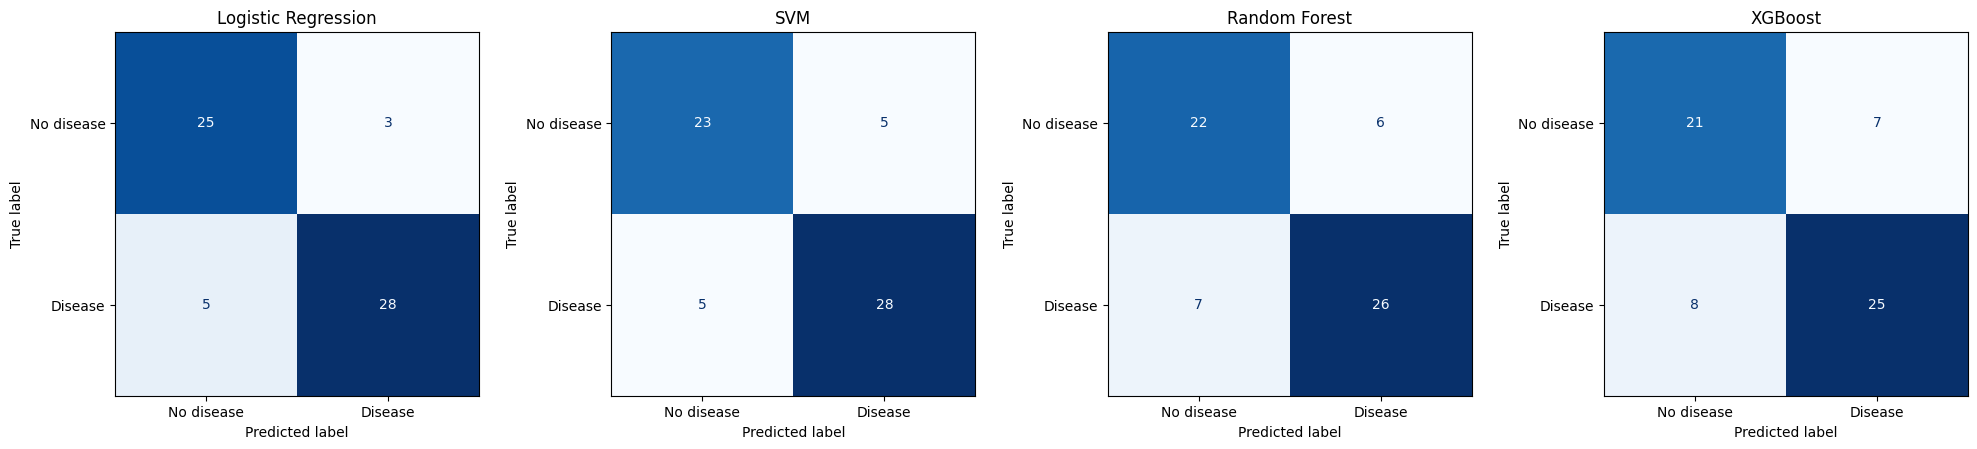

In [31]:
n = len(test_proba)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 4.5))
for ax, (name, proba) in zip(np.atleast_1d(axes), test_proba.items()):
    pred = (proba >= 0.5).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["No disease", "Disease"],
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 10. Detailed classification report for each algorithm

In [32]:
for name, proba in test_proba.items():
    pred = (proba >= 0.5).astype(int)
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred, target_names=["No disease", "Disease"]))

Logistic Regression
              precision    recall  f1-score   support

  No disease       0.83      0.89      0.86        28
     Disease       0.90      0.85      0.88        33

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61

SVM
              precision    recall  f1-score   support

  No disease       0.82      0.82      0.82        28
     Disease       0.85      0.85      0.85        33

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61

Random Forest
              precision    recall  f1-score   support

  No disease       0.76      0.79      0.77        28
     Disease       0.81      0.79      0.80        33

    accuracy                           0.79        61
   macro avg       0.79      0.79      0.79        61
weighted avg       0.79      0.79   

## 11. Feature importance (permutation importance, all algorithms)


In [40]:
# Check that the trained models exist
if "fitted" not in globals() or not fitted:
    raise RuntimeError(
        "Models are not trained yet. Run the model-training cell in Section 6 first."
    )

# Calculate permutation feature importance
importance_tables = {}

for name, model in fitted.items():
    print(f"Calculating feature importance: {name}")

    perm = permutation_importance(
        estimator=model,
        X=X_test,
        y=y_test,
        scoring="roc_auc",
        n_repeats=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importance_tables[name] = pd.Series(
        perm.importances_mean,
        index=X_test.columns
    )

# Combine all model results
importance_df = pd.DataFrame(importance_tables).round(4)

# Sort features by average importance across models
importance_df = importance_df.loc[
    importance_df.mean(axis=1)
    .sort_values(ascending=False)
    .index
]

# Save results
importance_df.to_csv("feature_importance_all_models.csv")

# Display the feature importance table
display(importance_df)

print("Feature importance saved successfully.")

Calculating feature importance: Logistic Regression
Calculating feature importance: SVM
Calculating feature importance: Random Forest
Calculating feature importance: XGBoost


ValueError: Pipeline should either be a classifier to be used with response_method=predict_proba or the response_method should be 'predict'. Got a regressor with response_method=predict_proba instead.

In [41]:
n = len(importance_df.columns)

fig, axes = plt.subplots(
    nrows=1,
    ncols=n,
    figsize=(max(6, 4.5 * n), 6),
    sharey=True,
    squeeze=False
)

axes = axes.ravel()

for ax, name in zip(axes, importance_df.columns):

    values = importance_df[name].sort_values(ascending=True)

    ax.barh(
        values.index,
        values.values,
        color="tab:blue"
    )

    ax.set_title(name)
    ax.set_xlabel("Mean decrease in ROC-AUC")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

axes[0].set_ylabel("Features")

plt.suptitle(
    "Permutation Feature Importance — Heart Disease Prediction",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "feature_importance_all_models.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

NameError: name 'importance_df' is not defined

## 12. Best algorithm and saving outputs

In [35]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted[best_name]
print(f"Best algorithm (by CV ROC-AUC): {best_name}")
print("Best hyperparameters:", results_df.iloc[0]["Best params"])
print("Test ROC-AUC:", round(results_df.iloc[0]["Test ROC-AUC"], 4))

joblib.dump(best_model, "best_heart_model.joblib")
print("Saved best_heart_model.joblib")

Best algorithm (by CV ROC-AUC): Logistic Regression
Best hyperparameters: {'clf__C': 1}
Test ROC-AUC: 0.9048
Saved best_heart_model.joblib


In [36]:
def predict_patient(model, patient: dict) -> float:
    """Return the predicted probability of heart disease for one patient.

    `patient` must contain all 13 feature names, e.g.
    {"age": 52, "sex": 1, "cp": 0, "trestbps": 125, "chol": 212, "fbs": 0,
     "restecg": 1, "thalach": 168, "exang": 0, "oldpeak": 1.0,
     "slope": 2, "ca": 2, "thal": 3}
    """
    row = pd.DataFrame([patient], columns=X.columns)
    return float(model.predict_proba(row)[0, 1])

example_idx = 0
example = X_test.iloc[example_idx].to_dict()
print(f"Predicted probability of disease: {predict_patient(best_model, example):.3f}")
print(f"Actual label: {int(y_test.iloc[example_idx])}")

Predicted probability of disease: 0.198
Actual label: 0


In [37]:
# Outputs are already saved in the notebook folder:
# model_comparison.csv, feature_importance_all_models.csv, best_heart_model.joblib

## 13. Conclusions

Read the comparison table in Section 7 and the cross-validation boxplot in Section 7 together:

- **CV ROC-AUC** is the main ranking metric, because it uses several folds of training data.
- **CV standard deviation** shows how stable each model is across folds. A high-scoring model with high variance is less reliable.
- **Test metrics** are a final check. With only about 60 test patients, small differences between models are not meaningful.
- **Recall** matters most clinically, since missing a sick patient is usually the costlier error.

This notebook is a research and learning prototype. It is not a clinical tool and needs external validation and regulatory review before any medical use.